In [1]:
# API key prompt for Groq API
import getpass
import os
if "GROQ_API_KEY" not in os.environ:
  os.environ["GROQ_API_KEY"] = getpass.getpass("Enter your Groq API key: ")

In [2]:
# intall the required packages
!pip install langchain-groq langgraph -quiet



Usage:   
  pip install [options] <requirement specifier> [package-index-options] ...
  pip install [options] -r <requirements file> [package-index-options] ...
  pip install [options] [-e] <vcs project url> ...
  pip install [options] [-e] <local project path> ...
  pip install [options] <archive url/path> ...

no such option: -u


In [3]:
# import the necessary classes from langchain_groq and langchain_core
from langchain_groq import ChatGroq
from langchain_core.messages import HumanMessage, AIMessage

In [4]:
# Reasoning Models with Action (ReAct) using LangGraph
# Allow an account-specific Groq model override; this default is available in this project.
model_name = os.getenv("GROQ_MODEL", "openai/gpt-oss-120b")
llm = ChatGroq(
    model=model_name,
    temperature=0,
    max_tokens=None,
    timeout=None,
    max_retries=2
)

In [5]:
if not os.environ.get("TAVILY_API_KEY"):
    os.environ["TAVILY_API_KEY"] = getpass.getpass("Tavily API key:\n")

In [6]:
import sys
!{sys.executable} -m pip install langchain-tavily

In [7]:
!pip install -U langchain_community

In [14]:
%pip install -q langchain-community

from langchain_tavily import TavilySearch
from langchain_community.document_loaders import WebBaseLoader
tavily_search = TavilySearch(
    max_results=3,
    search_depth="advanced",
    include_domains=["who.int"], # search WHO website only
    include_raw_content=True # show full result set false to defalt
)

Note: you may need to restart the kernel to use updated packages.


/var/folders/kt/_sqjpvvn68df8w2lj81nbvgm0000gp/T/ipykernel_4552/713311556.py:4: DeprecationWarning: `langchain-community` is being sunset and is no longer actively maintained. See https://github.com/langchain-ai/langchain-community/issues/674 for details and migration guidance toward standalone integration packages.
  from langchain_community.document_loaders import WebBaseLoader
USER_AGENT environment variable not set, consider setting it to identify your requests.


In [15]:
# Basic usage
question = "What is the latest WHO report on malaria?"
search_results = tavily_search.invoke(question)

In [16]:
search_results

{'query': 'What is the latest WHO report on malaria?',
 'follow_up_questions': None,
 'answer': None,
 'images': [],
 'results': [{'url': 'https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024',
   'title': 'World malaria report 2024',
   'content': 'New data from the WHO reveal that an estimated 2.2 billion cases of malaria and 12.7 million deaths have been averted since 2000, but the disease remains a serious global health threat, particularly in the WHO African Region. According to WHO’s latest World malaria report, there were an estimated 263 million cases and 597 000 malaria deaths worldwide in 2023. This represents about 11 million more cases in 2023 compared to 2022, and nearly the same number of deaths. Approximately 95% of the deaths occurred in the WHO African Region, where many at risk still lack access to the services they need to prevent, detect and treat the disease.\n\nReinvigorated global efforts needed to curb rising malaria threat\n\n## 

In [22]:
# Scrape pages linked in the search results
scraped_docs = []
urls = [result.get("url") for result in search_results["results"] if result.get("url")]
print(f"Found URLs: {urls}")

if not urls:
    print("No valid URLs in search results.")
else:
    for url in urls:
        try:
            print(f"Scraping {url}...")
            loader = WebBaseLoader(url)
            docs = loader.load()

            for doc in docs:
                doc.metadata["source"] = url

            scraped_docs.extend(docs)
        except Exception as e:
            print(f"Error scraping {url}: {e}")

print(f"Scraped {len(scraped_docs)} documents.")

Found URLs: ['https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024', 'https://www.who.int/news-room/fact-sheets/detail/malaria', 'https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2021']
Scraping https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024...
Scraping https://www.who.int/news-room/fact-sheets/detail/malaria...
Scraping https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2021...
Scraped 3 documents.


In [23]:
# view all docs stored
scraped_docs

[Document(metadata={'source': 'https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024', 'title': '\r\n\tWorld malaria report 2024\r\n', 'description': 'Each year, WHO’s World malaria report provides a comprehensive and up-to-date assessment of trends in malaria control and elimination across the globe', 'language': 'en'}, page_content='      \r\n\tWorld malaria report 2024\r\n                     \n   Skip to main content       \n\n\n \n\n\n\n\n\n\n\nGlobal\n\n\nRegions\n\n\n\n\n\n\n\nWHO Regional websites\n\n\n\n\n\n\n\nAfrica\n\n\n\n\n\nAmericas\n\n\n\n\n\nSouth-East Asia\n\n\n\n\n\nEurope\n\n\n\n\n\nEastern Mediterranean\n\n\n\n\n\nWestern Pacific\n\n\n\n\n\n\n\n\n\n   \n\n\n\n\n\n\n\n\n\n\n\n\n\nWhen autocomplete results are available use up and down arrows to review and enter to select.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\r\n        Select language\r\n    \n\nSelect language\nEnglish\nFrançais\nEspañol\n\n\n\n\n        \n            \n\n\n\n\n\n\n\n\n\n\n

In [24]:
# view single url
scraped_docs[0]

Document(metadata={'source': 'https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024', 'title': '\r\n\tWorld malaria report 2024\r\n', 'description': 'Each year, WHO’s World malaria report provides a comprehensive and up-to-date assessment of trends in malaria control and elimination across the globe', 'language': 'en'}, page_content='      \r\n\tWorld malaria report 2024\r\n                     \n   Skip to main content       \n\n\n \n\n\n\n\n\n\n\nGlobal\n\n\nRegions\n\n\n\n\n\n\n\nWHO Regional websites\n\n\n\n\n\n\n\nAfrica\n\n\n\n\n\nAmericas\n\n\n\n\n\nSouth-East Asia\n\n\n\n\n\nEurope\n\n\n\n\n\nEastern Mediterranean\n\n\n\n\n\nWestern Pacific\n\n\n\n\n\n\n\n\n\n   \n\n\n\n\n\n\n\n\n\n\n\n\n\nWhen autocomplete results are available use up and down arrows to review and enter to select.\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\n\r\n        Select language\r\n    \n\nSelect language\nEnglish\nFrançais\nEspañol\n\n\n\n\n        \n            \n\n\n\n\n\n\n\n\n\n\n 

In [25]:
from langchain_core.documents import Document
from typing import List
from typing_extensions import TypedDict

In [30]:
class GraphState(TypedDict):
    question: str
    documents: List[Document]
    sender: str # web_search_node

In [46]:
def web_search_node(state:GraphState) -> GraphState:
    """Searches the web for information, then scrapes the content from the resulting URLs."""
    print("--- Calling Web Search Node ---")
    question = state["question"]

    search_results = tavily_search.invoke(question)
    scraped_docs = []

    if not search_results or "results" not in search_results:
        print("No search results found.")
        return {"documents": [], "sender": "web_search_node"}

    urls = [result.get("url") for result in search_results["results"] if result.get("url")]
    print(f"Found URLs: {urls}")

    if not urls:
        print("No valid URLs in search results.")
        return {"documents": [], "sender": "web_search_node"}

    for url in urls:
        try:
            print(f"Scraping {url}...")
            loader = WebBaseLoader(url)
            docs = loader.load()

            for doc in docs:
                doc.metadata["source"] = url

            scraped_docs.extend(docs)
        except Exception as e:
            print(f"Error scraping {url}: {e}")

    return {"documents": scraped_docs, "sender": "web_search_node"}

In [47]:
# langgraph node import and connect this edge
from langgraph.graph import StateGraph, END

workflow = StateGraph(GraphState)

In [44]:
workflow.add_node ("web_search", web_search_node)
workflow.add_edge ("web_search", END)
workflow.set_entry_point ("web_search")
app = workflow.compile()


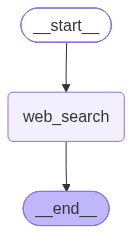

In [45]:
from IPython.display import Image, display
# view this graph how to work
display (Image(app.get_graph(xray=True).draw_mermaid_png()))

In [51]:
inputs = {"question": "What is the latest WHO report on malaria?"}
for output in app.stream(inputs):
    for key, value in output.items():
        print(f"\n---Output from Node: {key} ---")

    if 'documents' in value and value['documents']:
        print(f"Documents found: {len(value['documents'])}")
        print("_" * 30)

    for i, doc in enumerate(value['documents']):
        print(f"\n--- Document {i+1} ---")
        print(f"Source: {doc.metadata.get('source', 'No source available')}")
        # print ("\InContent:")
        # print (doc. page_content)
    else:
        print("No documents found in this step.")

--- Calling Web Search Node ---
Found URLs: ['https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024', 'https://www.who.int/news-room/fact-sheets/detail/malaria', 'https://www.afro.who.int/publications/world-malaria-report-2015']
Scraping https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024...
Scraping https://www.who.int/news-room/fact-sheets/detail/malaria...
Scraping https://www.afro.who.int/publications/world-malaria-report-2015...

---Output from Node: web_search ---
Documents found: 3
______________________________

--- Document 1 ---
Source: https://www.who.int/teams/global-malaria-programme/reports/world-malaria-report-2024

--- Document 2 ---
Source: https://www.who.int/news-room/fact-sheets/detail/malaria

--- Document 3 ---
Source: https://www.afro.who.int/publications/world-malaria-report-2015
No documents found in this step.
